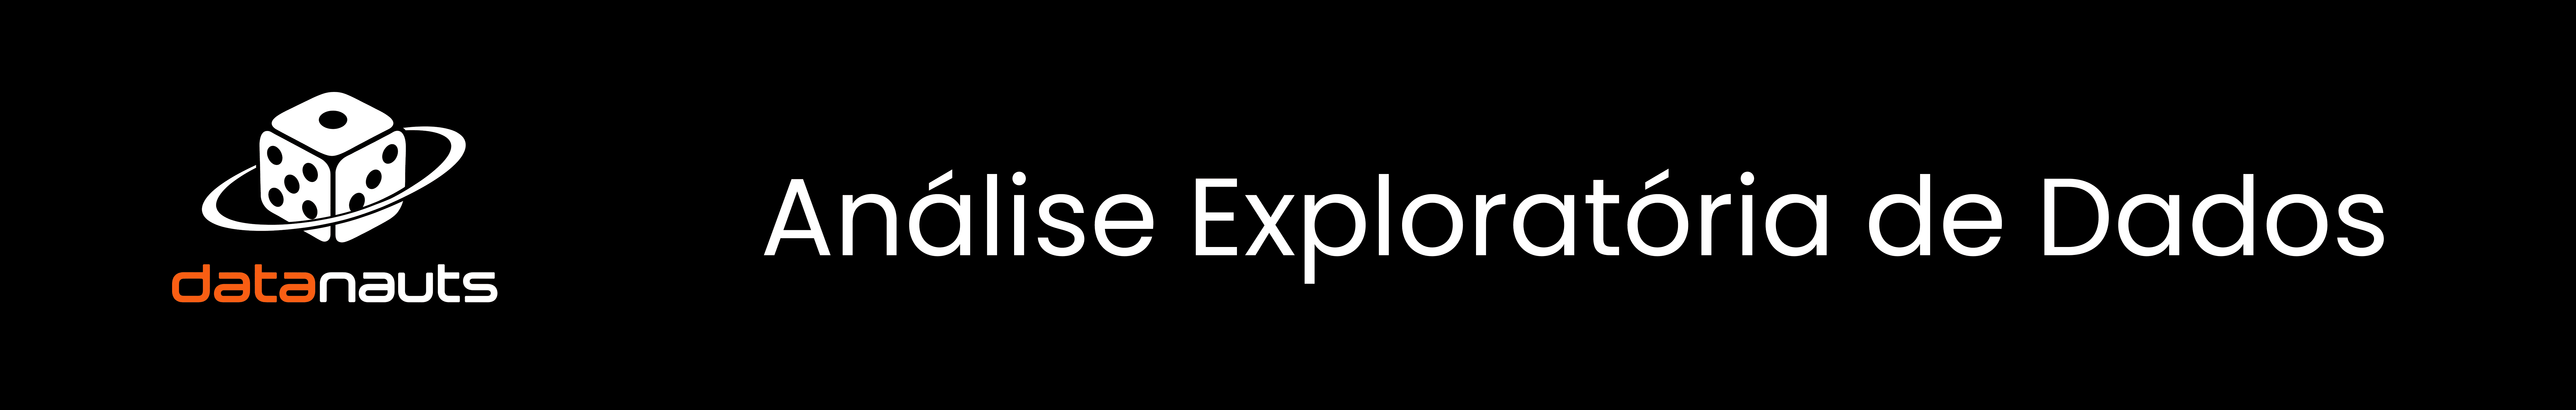


O desafio do Datathon Impacta.dev, promovido pela FEA.dev com o apoio da SempreFEA, propõe a seguinte questão: *O que os dados revelam sobre a evasão no ensino superior e como podemos evitá-la?*.

Dessa forma, neste projeto, analisaremos crítica e quantitativamente os dados para identificar o problema determinante da evasão no ensino superior e, por fim, propor uma solução viável, clara e aplicável.

Neste notebook, realizaremos uma análise exploratória de dados com o objetivo de identificar padrões associados aos estudantes que abandonam o ensino superior. Consideraremos como desistência os alunos com status de "Desvinculado", isto é, aqueles que perderam o vínculo com o curso por abandono, cancelamento, jubilamento ou outro motivo, sem a conclusão da graduação.

### Entendendo os dados

- Os dados foram disponibilizados pela FEA.dev: https://drive.google.com/drive/folders/1c03nHdnTe-2cczVjagfAF0d7E-U4LGeS?usp=sharing
- Os dados têm origem nos microdados do Censo da Educação Superior (INEP) de 2020 a 2024, complementado por outros indicadores do INEP, do IBGE e do Portal da Transparência.

In [5]:
import pandas as pd
cursos = pd.read_parquet("..\\data\\raw\\cursos_ano.parquet")

pd.set_option('display.max_columns', None)
cursos.head()

,ano,co_curso,nome_curso,co_ies,nome_ies,sigla_ies,uf_sede_ies,rede,categoria_administrativa,organizacao_academica,modalidade,grau_academico,gratuito,cine_area_geral,nome_cine_area_geral,cine_area_especifica,nome_cine_area_especifica,cine_rotulo,nome_cine_rotulo,cine_rotulo_original,uf_principal,regiao_principal,co_municipio,municipio,n_ufs_oferta,n_municipios_oferta,vagas,inscritos,ingressantes,matriculas,concluintes,trancados,desvinculados,transferidos,falecidos,mat_feminino,mat_noturno,mat_ppi,mat_25_anos_ou_mais,mat_escola_publica,mat_deficiencia,mat_apoio_social,mat_fies,mat_prouni,mat_reserva_vagas,vinculos,taxa_desvinculo,taxa_trancamento,taxa_conclusao_anual,poucos_alunos,anos_com_alunos,primeiro_ano,ultimo_ano,presente_5_anos
0,2020,1,Direito,1,UNIVERSIDADE FEDERAL DE MATO GROSSO,UFMT,MT,Pública,Pública Federal,Universidade,Presencial,Bacharelado,1,04,"Negócios, administração e direito",042,Direito,0421D01,Direito,0421D01,MT,Centro-Oeste,5103403,Cuiabá,1,1,100,3168,100,453,27,70,3,0,0,203,225,244,122,238,11,10,0,0,223,526,0.0057,0.1331,0.0513,0,5,2020,2024,1
1,2021,1,Direito,1,UNIVERSIDADE FEDERAL DE MATO GROSSO,UFMT,MT,Pública,Pública Federal,Universidade,Presencial,Bacharelado,1,04,"Negócios, administração e direito",042,Direito,0421D01,Direito,0421D01,MT,Centro-Oeste,5103403,Cuiabá,1,1,104,1850,104,426,7,100,8,0,0,184,195,227,104,231,13,0,0,0,216,534,0.0150,0.1873,0.0131,0,5,2020,2024,1
2,2022,1,Direito,1,UNIVERSIDADE FEDERAL DE MATO GROSSO,UFMT,MT,Pública,Pública Federal,Universidade,Presencial,Bacharelado,1,04,"Negócios, administração e direito",042,Direito,0421D01,Direito,0421D01,MT,Centro-Oeste,5103403,Cuiabá,1,1,104,689,105,452,88,113,17,0,0,203,214,240,111,237,13,30,0,0,225,582,0.0292,0.1942,0.1512,0,5,2020,2024,1
3,2023,1,Direito,1,UNIVERSIDADE FEDERAL DE MATO GROSSO,UFMT,MT,Pública,Pública Federal,Universidade,Presencial,Bacharelado,1,04,"Negócios, administração e direito",042,Direito,0421D01,Direito,0421D01,MT,Centro-Oeste,5103403,Cuiabá,1,1,104,1651,103,446,74,84,50,0,0,199,217,229,119,238,20,46,0,0,228,580,0.0862,0.1448,0.1276,0,5,2020,2024,1
4,2024,1,Direito,1,UNIVERSIDADE FEDERAL DE MATO GROSSO,UFMT,MT,Pública,Pública Federal,Universidade,Presencial,Bacharelado,1,04,"Negócios, administração e direito",042,Direito,0421D01,Direito,0421D01,MT,Centro-Oeste,5103403,Cuiabá,1,1,111,1160,118,460,70,103,9,0,0,208,216,241,116,236,20,68,0,0,274,572,0.0157,0.1801,0.1224,0,5,2020,2024,1



### Dicionário dos dados da tabela cursos_ano.parquet


1. **ano**: Ano de referência do Censo (2020-2024).
2. **co_curso**: Código do curso no INEP. Estável entre os anos: dá para usar para seguir o mesmo curso no tempo.
3. **nome_curso**: Nome do curso (grafia do ano mais recente em que o curso aparece).
4. **co_ies**: Código da instituição (IES) no INEP.
5. **nome_ies**: Nome completo da instituição.
6. **sigla_ies**: Sigla cadastrada da instituição.
7. **uf_sede_ies**: Sigla da Unidade da Federação (UF) onde fica a sede da instituição.
8. **rede**: Rede de ensino da instituição: Pública ou Privada.
9. **categoria_administrativa**: Categoria administrativa da instituição: Pública Federal, Pública Estadual, Pública Municipal, Privada com fins lucrativos, Privada sem fins lucrativos ou Especial.
10. **organizacao_academica**: Tipo de organização acadêmica da instituição: Universidade, Centro Universitário, Faculdade, Instituto Federal ou CEFET.
11. **modalidade**: Modalidade de ensino do curso: Presencial ou EAD (educação a distância).
12. **grau_academico**: Grau acadêmico do curso: Bacharelado, Licenciatura, Tecnológico, Bacharelado e Licenciatura ou Não aplicável (ABI).
13. **gratuito**: Indica se o curso é gratuito: 1 = sim; 0 = não.
14. **cine_area_geral**: Código da área geral de conhecimento do curso na classificação Cine Brasil (por exemplo, 04).
15. **nome_cine_area_geral**: Nome da área geral de conhecimento da Cine Brasil (por exemplo, Negócios, administração e direito).
16. **cine_area_especifica**: Código da área específica na classificação Cine Brasil (por exemplo, 042).
17. **nome_cine_area_especifica**: Nome da área específica da Cine Brasil (por exemplo, Direito).
18. **cine_rotulo**: Código do rótulo mais detalhado da Cine Brasil (por exemplo, 0421D01). Foi harmonizado usando a classificação mais recente do curso para permitir comparações no tempo.
19. **nome_cine_rotulo**: Nome correspondente ao rótulo mais detalhado da Cine Brasil.
20. **cine_rotulo_original**: Rótulo da Cine Brasil atribuído pelo INEP ao curso no ano da observação, antes da harmonização.
21. **uf_principal**: UF principal onde o curso é oferecido. Para cursos EAD em várias UFs, é a UF com mais alunos.
22. **regiao_principal**: Região geográfica correspondente à UF principal de oferta do curso.
23. **co_municipio**: Código IBGE do município de oferta do curso. Informado para cursos presenciais; vazio nos cursos EAD.
24. **municipio**: Nome do município onde o curso presencial é oferecido. Vazio nos cursos EAD.
25. **n_ufs_oferta**: Quantidade de UFs em que o curso tem local de oferta/alunos no ano.
26. **n_municipios_oferta**: Quantidade de municípios em que o curso tem local de oferta no ano.
27. **vagas**: Número de vagas oferecidas pelo curso no ano.
28. **inscritos**: Número de candidatos inscritos nos processos seletivos do curso.
29. **ingressantes**: Número de alunos que ingressaram no curso naquele ano.
30. **matriculas**: Número de alunos em situação de cursando ou formado no ano. Não inclui trancados, desvinculados, transferidos ou falecidos.
31. **concluintes**: Número de alunos que concluíram o curso no ano. Estão incluídos em matriculas.
32. **trancados**: Número de alunos com matrícula trancada no ano.
33. **desvinculados**: Número de alunos que perderam o vínculo com o curso no ano, por abandono, desistência, jubilamento ou outro motivo.
34. **transferidos**: Número de alunos transferidos para outro curso da mesma instituição.
35. **falecidos**: Número de alunos falecidos no ano.
36. **mat_feminino**: Número de matriculadas do sexo feminino.
37. **mat_noturno**: Número de matriculados no turno noturno. Para EAD, o valor é sempre 0.
38. **mat_ppi**: Número de matriculados pretos, pardos ou indígenas (PPI).
39. **mat_25_anos_ou_mais**: Número de matriculados com 25 anos de idade ou mais.
40. **mat_escola_publica**: Número de matriculados que cursaram o ensino médio em escola pública.
41. **mat_deficiencia**: Número de matriculados com deficiência, transtorno global do desenvolvimento ou altas habilidades/superdotação.
42. **mat_apoio_social**: Número de matriculados que recebem apoio social da instituição ou de programa público, como alimentação, moradia, transporte ou bolsa permanência. O valor 0 também pode indicar ausência de informação.
43. **mat_fies**: Número de matriculados com financiamento pelo FIES.
44. **mat_prouni**: Número de matriculados com bolsa integral ou parcial do ProUni.
45. **mat_reserva_vagas**: Número de matriculados que ingressaram por ação afirmativa ou programa de reserva de vagas (cotas).
46. **vinculos**: Total de alunos com vínculo no curso no ano: matriculas + trancados + desvinculados + transferidos + falecidos.
47. **taxa_desvinculo**: Proporção de alunos com vínculo que se desvincularam do curso no ano. Fórmula: desvinculados / vinculos. Varia de 0 a 1.
48. **taxa_trancamento**: Proporção de alunos com vínculo que trancaram matrícula no ano. Fórmula: trancados / vinculos. Varia de 0 a 1.
49. **taxa_conclusao_anual**: Proporção de alunos com vínculo que concluíram o curso no ano. Fórmula: concluintes / vinculos. Varia de 0 a 1.
50. **poucos_alunos**: Sinaliza cursos com menos de 30 vínculos no ano: 1 = menos de 30; 0 = 30 ou mais.
51. **anos_com_alunos**: Quantidade de anos, entre 2020 e 2024, em que o curso aparece com alunos (de 1 a 5).
52. **primeiro_ano**: Primeiro ano, no período de 2020 a 2024, em que o curso aparece com alunos.
53. **ultimo_ano**: Último ano, no período de 2020 a 2024, em que o curso aparece com alunos.
54. **presente_5_anos**: Indica se o curso aparece com alunos em todos os cinco anos de 2020 a 2024: 1 = sim; 0 = não.